# Data exploration

## Dependencies import

In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print(f"NumPy: {np.__version__}")
print(f"pandas: {pd.__version__}")

NumPy: 2.5.4
pandas: 3.1.1


## Initial Data Review

In [42]:
# Since the dataset file is saved in the Strict Open XML Spreadsheet format, we
# have to use `calamine` to read it
df = pd.read_excel("dataset/dataset-uci.xlsx", engine="calamine")

# Shape of dataset; data types; feature overview; missing values; duplicates; etc.
rows = len(df)
print(f"Number of rows: {rows}")
# how many columns we have of data
columns = len(df.columns)
print(f"Number of columns: {columns}")

print(f"Dataset shape: {df.shape}")
print(f"Dataset datatypes:\n{df.dtypes}")

Number of rows: 319
Number of columns: 39
Dataset shape: (319, 39)
Dataset datatypes:
Gallstone Status                                    int64
Age                                                 int64
Gender                                              int64
Comorbidity                                         int64
Coronary Artery Disease (CAD)                       int64
Hypothyroidism                                      int64
Hyperlipidemia                                      int64
Diabetes Mellitus (DM)                              int64
Height                                              int64
Weight                                            float64
Body Mass Index (BMI)                             float64
Total Body Water (TBW)                            float64
Extracellular Water (ECW)                         float64
Intracellular Water (ICW)                         float64
Extracellular Fluid/Total Body Water (ECF/TBW)    float64
Total Body Fat Ratio (TBFR) (%)             

## Cleaning

In [43]:
print(f"# null values for each feature:\n{df.isnull().sum()}")
print(f"# null values: {df.isnull().sum().sum()}")

print(f"# duplicated values: {df.duplicated().sum()}")

# null values for each feature:
Gallstone Status                                  0
Age                                               0
Gender                                            0
Comorbidity                                       0
Coronary Artery Disease (CAD)                     0
Hypothyroidism                                    0
Hyperlipidemia                                    0
Diabetes Mellitus (DM)                            0
Height                                            0
Weight                                            0
Body Mass Index (BMI)                             0
Total Body Water (TBW)                            0
Extracellular Water (ECW)                         0
Intracellular Water (ICW)                         0
Extracellular Fluid/Total Body Water (ECF/TBW)    0
Total Body Fat Ratio (TBFR) (%)                   0
Lean Mass (LM) (%)                                0
Body Protein Content (Protein) (%)                0
Visceral Fat Rating (VFR)       

## Visualization

In [44]:
y = df["Gallstone Status"]
X = df.drop(columns="Gallstone Status")

First let's take a look at how the target distribution looks like

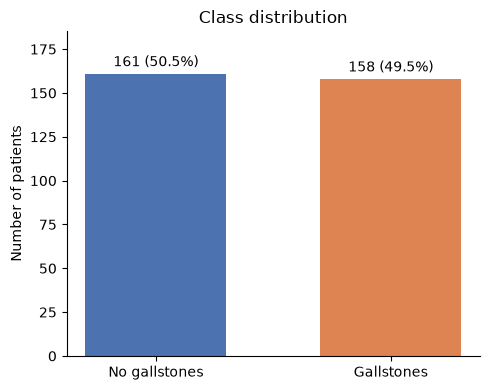

In [ ]:
counts = y.value_counts().sort_index()

names = {0: "No gallstones", 1: "Gallstones"}

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar([names[i] for i in counts.index], counts.values,
              color=["#4C72B0", "#DD8452"], width=0.6)

ax.bar_label(bars, labels=[f"{v} ({v / counts.sum():.1%})" for v in counts.values],
             padding=3)
ax.set_ylabel("Number of patients")
ax.set_title("Class distribution")
ax.set_ylim(0, counts.max() * 1.15)          # room for the labels above the bars
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

It looks very balanced. Let's now look at the target distribution by Sex

Gallstone Status  No gallstones  Gallstones
Gender                                     
Male                         94          68
Female                       67          90


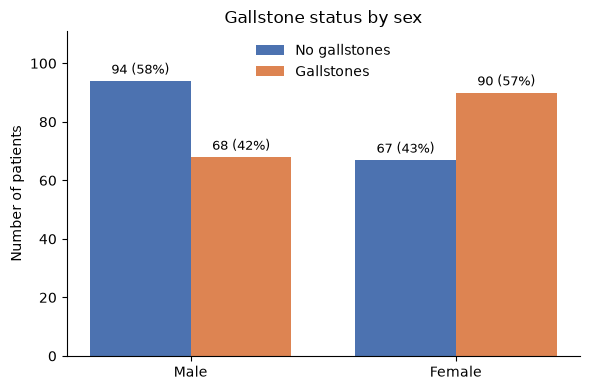

In [ ]:
sex = X["Gender"].map({0: "Male", 1: "Female"})
status = y.map(names)          # same `names` mapping as before

ct = pd.crosstab(sex, status).loc[["Male", "Female"], ["No gallstones", "Gallstones"]]
print(ct)

fig, ax = plt.subplots(figsize=(6, 4))
x = np.arange(len(ct.index))
w = 0.38

for i, (col, color) in enumerate(zip(ct.columns, ["#4C72B0", "#DD8452"])):
    vals = ct[col].values
    share = vals / ct.sum(axis=1).values        # share within each sex
    bars = ax.bar(x + (i - 0.5) * w, vals, w, label=col, color=color)
    ax.bar_label(bars, labels=[f"{v} ({s:.0%})" for v, s in zip(vals, share)],
                 padding=3, fontsize=9)

ax.set_xticks(x, ct.index)
ax.set_ylabel("Number of patients")
ax.set_title("Gallstone status by sex")
ax.set_ylim(0, ct.values.max() * 1.18)
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

## Preprocessing

### Outliers handling

First we compute the standard deviation of each feature and find the outliers records

In [47]:
# Outlier
v_max =  X.max()
v_mean = X.mean()
v_min =  X.min()
v_std =  X.std()

z = (X - v_mean) / v_std
outliers = z.abs() > 10

outliers.sum()               # number of outliers per column

Age                                               0
Gender                                            0
Comorbidity                                       0
Coronary Artery Disease (CAD)                     0
Hypothyroidism                                    0
Hyperlipidemia                                    0
Diabetes Mellitus (DM)                            0
Height                                            0
Weight                                            0
Body Mass Index (BMI)                             0
Total Body Water (TBW)                            0
Extracellular Water (ECW)                         0
Intracellular Water (ICW)                         0
Extracellular Fluid/Total Body Water (ECF/TBW)    0
Total Body Fat Ratio (TBFR) (%)                   0
Lean Mass (LM) (%)                                0
Body Protein Content (Protein) (%)                0
Visceral Fat Rating (VFR)                         0
Bone Mass (BM)                                    0
Muscle Mass 

In [48]:
result = pd.DataFrame({
    "value": X[outliers].stack().dropna(),
    "z": z[outliers].stack().dropna(),
})

feature = result.index.get_level_values(1)
result["mean"] = v_mean[feature].values
result["std"] = v_std[feature].values

result = result[["value", "mean", "std", "z"]].rename_axis(["Record", "Feature"])
result.round(2)

value    mean     std      z
Record Feature                                                      
40     Glucose                          575.0  108.69   44.85  10.40
239    Obesity (%)                     1954.0   35.85  109.80  17.47
278    Aspartat Aminotransferaz (AST)   195.0   21.68   16.70  10.38
       Alanin Aminotransferaz (ALT)     372.0   26.86   27.88  12.38
318    High Density Lipoprotein (HDL)   273.0   49.48   17.72  12.62

A Glucose level of 575 is an absordly high value. The patient should be have diabetis, but it doesn't so we'll drop it

In [49]:
X = X.drop(40)
y = y.drop(40)

This is probably just a sign error

In [50]:
X.loc[239, "Obesity (%)"] = 19.54

This value is unreasonable

In [51]:
X = X.drop(318)
y = y.drop(318)

### Skewed features

In [52]:
# Continuous features only (binary and ordinal ones have ≤ 5 distinct values)
cont = [c for c in X.columns if X[c].nunique() > 5]

skew = X[cont].skew()
skewed = skew[skew > 1].index.tolist()             # strongly right-skewed
skewed = [c for c in skewed if (X[c] >= 0).all()]  # log1p needs x > -1

skew_table = pd.DataFrame({
    "Skewness": skew[skewed],
    "After log": np.log1p(X[skewed]).skew(),
}).sort_values("Skewness", ascending=False).round(2)

skew_table
#print(skew_table.to_latex())

,Skewness,After log
Alanin Aminotransferaz (ALT),7.36,0.92
Aspartat Aminotransferaz (AST),6.98,1.74
C-Reactive Protein (CRP),5.39,1.68
Glucose,4.56,2.87
Triglyceride,2.80,-0.63
Obesity (%),1.15,-0.89
Visceral Fat Area (VFA),1.05,-0.76


## Feature Selection

In [53]:
# Highly correlated features
corr = X.corr().abs()
upper = corr.where(np.triu(
    np.ones(corr.shape, dtype=bool),
    k=1
))  # upper triangle only

pairs = upper.stack()
high = pairs[pairs > 0.9]
high.sort_values(key=np.abs, ascending=False)

Total Body Fat Ratio (TBFR) (%)  Lean Mass (LM) (%)           0.994034
Total Body Water (TBW)           Muscle Mass (MM)             0.928283
Body Mass Index (BMI)            Obesity (%)                  0.917529
Total Body Water (TBW)           Extracellular Water (ECW)    0.904031
Intracellular Water (ICW)        Muscle Mass (MM)             0.903599
Body Mass Index (BMI)            Total Fat Content (TFC)      0.902578
dtype: float64

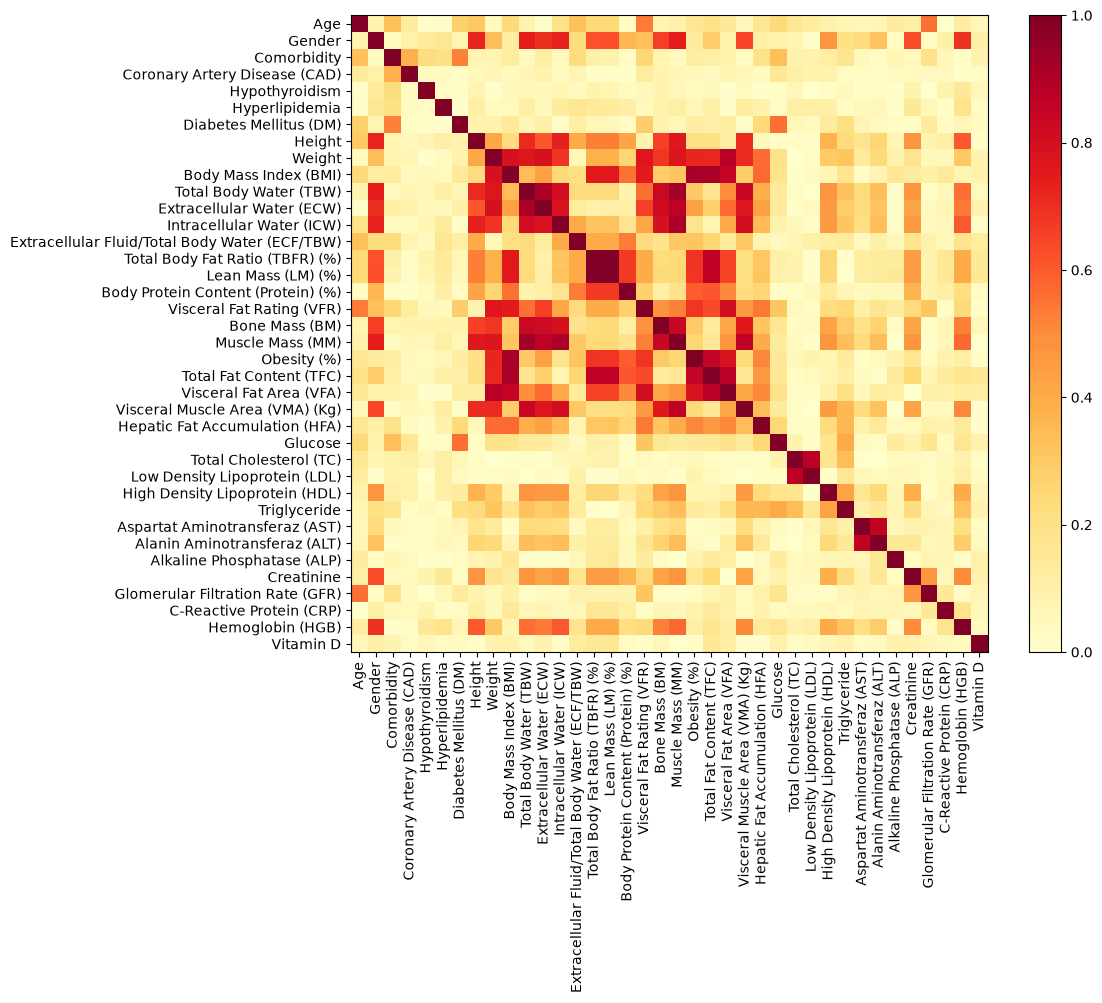

In [54]:
plt.figure(figsize=(12, 10))
plt.imshow(corr, cmap="YlOrRd", vmin=0, vmax=1)
plt.colorbar()
plt.xticks(range(len(X.columns)), X.columns, rotation=90)
plt.yticks(range(len(X.columns)), X.columns)
plt.tight_layout()
plt.show()

In [55]:
keep = []
for c in X.columns:
    if not (corr.loc[c, keep] > 0.9).any():
        keep.append(c)

dropped = [c for c in X.columns if c not in keep]
print(f"Dropped {len(dropped)}:", dropped)

X = X[keep]

Dropped 5: ['Extracellular Water (ECW)', 'Lean Mass (LM) (%)', 'Muscle Mass (MM)', 'Obesity (%)', 'Total Fat Content (TFC)']
